# PyTorch — L’essentiel du framework

**Objectifs :**
- comprendre les `Tensor` ;
- utiliser `Autograd` ;
- construire un modèle avec `nn.Module` ;
- définir un `Loss` et un `Optimizer` ;
- écrire une boucle d’apprentissage ;
- distinguer `train()` et `eval()` ;
- utiliser `Dataset` / `DataLoader` ;
- entraîner un exemple de régression et un exemple de classification ;
- sauvegarder et recharger un modèle.

## 0. Préparation

Le notebook fonctionne sur CPU. S’il existe un GPU CUDA, PyTorch pourra l’utiliser automatiquement.

In [47]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch version: 2.10.0
CUDA disponible: False


## 1. Workflow général

Le cycle de base est :

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

In [48]:
# Pseudo-code de la logique générale
# y_pred = model(X)
# loss = criterion(y_pred, y)
# optimizer.zero_grad()
# loss.backward()
# optimizer.step()

## 2. Les Tensors

Un `Tensor` est la structure de données fondamentale de PyTorch.

In [49]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar:", scalar, "shape =", scalar.shape)
print("vector:", vector, "shape =", vector.shape)
print("matrix:", matrix, "shape =", matrix.shape)
print("dtype:", matrix.dtype)
print("ndim:", matrix.ndim)

scalar: tensor(3.) shape = torch.Size([])
vector: tensor([1., 2., 3.]) shape = torch.Size([3])
matrix: tensor([[1., 2.],
        [3., 4.]]) shape = torch.Size([2, 2])
dtype: torch.float32
ndim: 2


### Manipulation de Tensors

In [50]:
x = torch.arange(12)
print("x =", x)

x2 = x.reshape(3, 4)
print("reshape(3,4):", x2)

print("Colonne 1:", x2[:, 1])
print("Ligne 0:", x2[0, :])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("A @ B =", A @ B)

print("mean(A) =", A.mean())
print("sum(A) =", A.sum())

x = tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3,4): tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Colonne 1: tensor([1, 5, 9])
Ligne 0: tensor([0, 1, 2, 3])
A @ B = tensor([[ 4.,  4.],
        [10.,  8.]])
mean(A) = tensor(2.5000)
sum(A) = tensor(10.)


## 3. CPU, GPU et `device`

In [51]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé:", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

Device utilisé: cpu
x.device = cpu


## 4. Autograd

`Autograd` calcule automatiquement les dérivées à partir du graphe de calcul.

In [52]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

loss.backward()

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", w.grad.item())
print("dLoss/db =", b.grad.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


In [53]:
import torch

x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

dw, db = torch.autograd.grad(loss, (w, b))

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", dw.item())
print("dLoss/db =", db.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


### Vérification analytique

Ici :

\[
y = wx+b
\]

et

\[
L=(y-10)^2
\]

Donc :

\[

rac{\partial L}{\partial w}=2(y-10)x
\]

\[

rac{\partial L}{\partial b}=2(y-10)
\]

In [54]:
y_val = (3.0 * 2.0 + 1.0)
dL_dw = 2 * (y_val - 10) * 2.0
dL_db = 2 * (y_val - 10)
print(dL_dw, dL_db)

-12.0 -6.0


## 5. Un neurone avec `nn.Linear`

Un neurone linéaire calcule essentiellement :

\[
z = \sum_i w_i x_i + b
\]

In [55]:
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

Sortie: tensor([[0.1135]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[ 0.1652, -0.1261,  0.2248]], requires_grad=True)
Biais: Parameter containing:
tensor([-0.4738], requires_grad=True)


In [56]:
import torch
import torch.nn as nn
from torchviz import make_dot

model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

dot = make_dot(y, params=dict(model.named_parameters()))
dot.render("graphe_operations", format="png", cleanup=True)

Sortie: tensor([[-0.5975]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[ 0.4286, -0.4238, -0.0997]], requires_grad=True)
Biais: Parameter containing:
tensor([0.1206], requires_grad=True)


'graphe_operations.png'

## 6. Construire un réseau avec `nn.Module`

In [57]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [58]:
model = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)


## 7. Fonctions d’activation

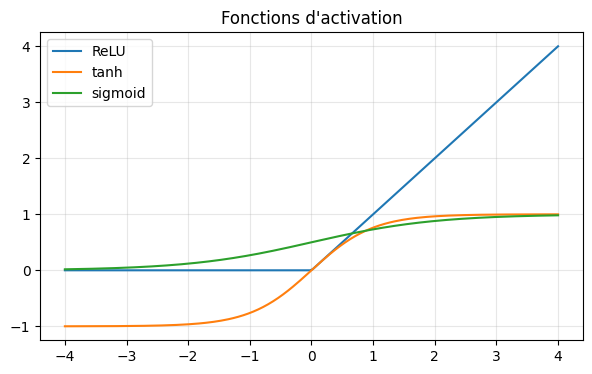

In [59]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), relu.numpy(), label='ReLU')
plt.plot(x.numpy(), tanh.numpy(), label='tanh')
plt.plot(x.numpy(), sigmoid.numpy(), label='sigmoid')
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()

## 8. Forward propagation

L’appel `model(X)` déclenche automatiquement `model.forward(X)`.

In [60]:
X = torch.randn(5, 4)
# L’appel model(X) déclenche automatiquement model.forward(X)
predicted = model(X)
print("Shape entrée :", X.shape)
print("Shape sortie :", predicted.shape)

Shape entrée : torch.Size([5, 4])
Shape sortie : torch.Size([5, 3])


## 9. Fonctions de coût

Cas principaux :
- régression : `nn.MSELoss()` ;
- classification multi-classe : `nn.CrossEntropyLoss()` ;
- classification binaire : `nn.BCEWithLogitsLoss()`.

In [61]:
# Régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())

# Classification multi-classe
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())

MSE = 1.0
CrossEntropy = 0.36905235052108765


## 10. Optimizers

L’optimiseur utilise les gradients pour mettre à jour les paramètres.

In [62]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## 11. La boucle d’apprentissage

C’est le cœur de PyTorch.

In [63]:
X = torch.randn(8, 1)
y = 2 * X + 1
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()
epochs = 500
# Exemple générique
for epoch in range(epochs):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 ==0 : 
        print(f"epoch={epoch} loss={loss.item():.4f}")

epoch=0 loss=14.4736
epoch=100 loss=6.4417
epoch=200 loss=2.4459
epoch=300 loss=0.7627
epoch=400 loss=0.1909


## 12. `train()` vs `eval()`

`model.train()` et `model.eval()` influencent notamment le comportement de `Dropout` et `BatchNorm`.

`eval()` ne désactive pas le calcul des gradients. Pour l’inférence, on utilise généralement `torch.inference_mode()`.

In [64]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))

m.eval()
with torch.inference_mode():
    print("eval()  :", m(x))

train() : tensor([2., 2., 0., 0., 2., 0., 2., 2., 2., 0.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 13. Dataset et DataLoader

In [65]:
X = torch.randn(100, 3)
y = torch.randn(100, 1)

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

for X_batch, y_batch in loader:
    print("Batch X:", X_batch.shape, "Batch y:", y_batch.shape)
    break

Batch X: torch.Size([16, 3]) Batch y: torch.Size([16, 1])


# Partie pratique 1 — Régression linéaire

Nous générons des données proches de :

\[
y = 3x + 2 + bruit
\]

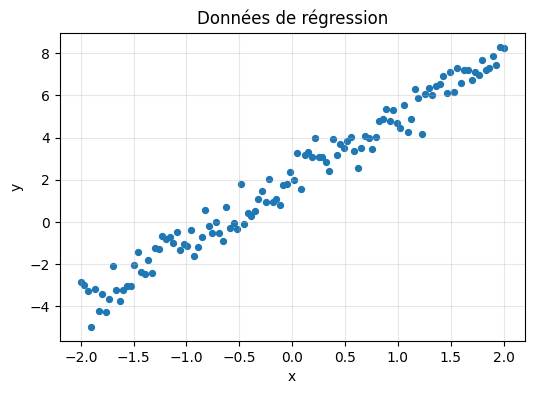

In [66]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Modèle, loss et optimizer

In [67]:
model_reg = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

## 15. Entraînement de la régression

In [68]:
losses = []

for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Dernier loss:", losses[-1])
print("w appris:", model_reg.weight.item())
print("b appris:", model_reg.bias.item())

Dernier loss: 0.3438418209552765
w appris: 2.9894580841064453
b appris: 2.030014753341675


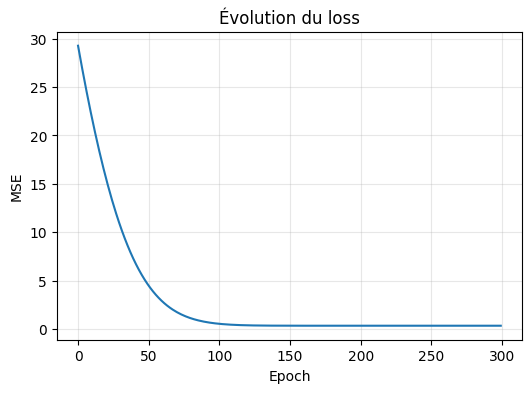

In [69]:
plt.figure(figsize=(6,4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Évolution du loss")
plt.grid(True, alpha=0.3)
plt.show()

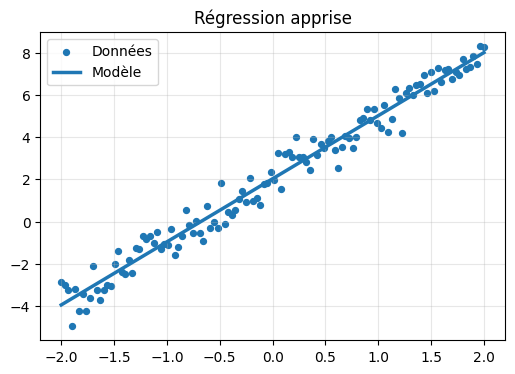

In [70]:
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X)

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.numpy(), linewidth=2.5, label="Modèle")
plt.legend()
plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

In [71]:
from torcheval.metrics import R2Score
metric = R2Score()
metric.update(y_hat,y)
r2=metric.compute()
print(f"R2 Score = {r2:.3f}")

R2 Score = 0.972


# Partie pratique 2 — Classification

Créons deux classes de points en 2D.

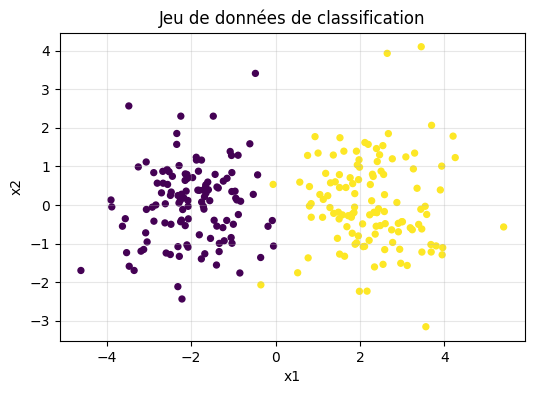

In [72]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long)
])

plt.figure(figsize=(6,4))
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Jeu de données de classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 16. Modèle de classification

In [73]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier()
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

## 17. Entraînement de la classification

In [74]:
losses_cls = []

for epoch in range(250):
    model_cls.train()

    logits = model_cls(X_cls)
    loss = criterion_cls(logits, y_cls)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())

print("Dernier loss:", losses_cls[-1])

Dernier loss: 0.0006943692569620907


In [75]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(X_cls)
    pred = logits.argmax(dim=1)
    accuracy = (pred == y_cls).float().mean()

print(f"Accuracy = {accuracy.item()*100:.2f}%")

Accuracy = 100.00%


Accuracy = 1.0000, recall= 1.0000, precision=1.0000, f1score=1.0000
tensor([[120,   0],
        [  0, 120]])


(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

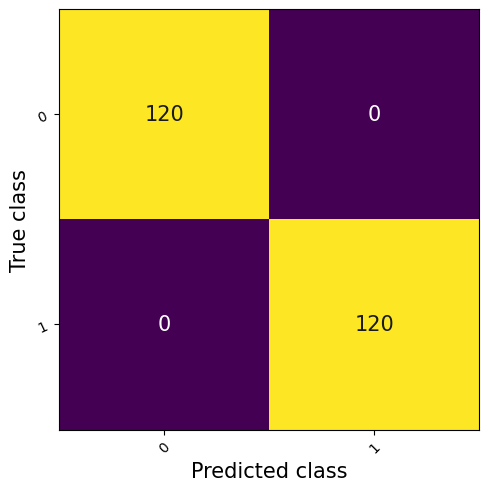

In [82]:
from torcheval.metrics import BinaryAccuracy, BinaryRecall, BinaryPrecision, BinaryPrecision, BinaryF1Score
from torchmetrics.classification import MulticlassConfusionMatrix, BinaryConfusionMatrix
accuracy_metric = BinaryAccuracy()
accuracy_metric.update(y_cls,pred)
accuracy_value = accuracy_metric.compute()

recall_metric = BinaryRecall()
recall_metric.update(y_cls, pred)
recall_value = recall_metric.compute()

precision_metric = BinaryPrecision()
precision_metric.update(y_cls,pred)
precision_value = precision_metric.compute()

f1_score_metric = BinaryF1Score()
f1_score_metric.update(y_cls, pred)
f1_score_value = f1_score_metric.compute()
print(f"Accuracy = {accuracy_value:.4f}, recall= {recall_value:.4f}, precision={precision_value:.4f}, f1score={f1_score_value:.4f}")

metric = BinaryConfusionMatrix()
confusion_matrix = metric(pred, y_cls)
print(confusion_matrix)
metric.plot()

## Visualisation de la frontière de décision

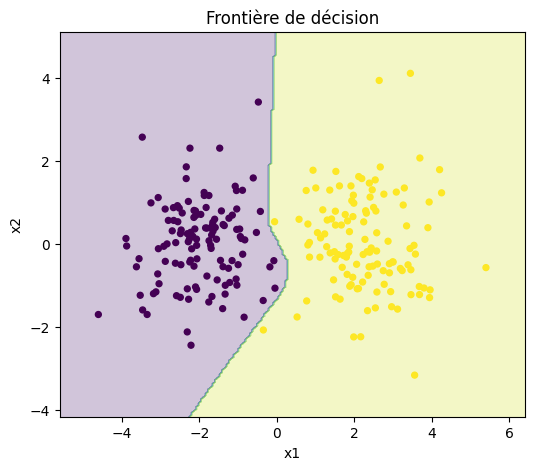

In [77]:
x1_min, x1_max = X_cls[:,0].min()-1, X_cls[:,0].max()+1
x2_min, x2_max = X_cls[:,1].min()-1, X_cls[:,1].max()+1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing='ij'
)

grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape)

plt.figure(figsize=(6,5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

## 18. Sauvegarder et recharger un modèle

In [78]:
path = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), path)
print("Modèle sauvegardé dans", path)

new_model = Classifier()
new_model.load_state_dict(torch.load(path, weights_only=True))
new_model.eval()

with torch.inference_mode():
    pred_new = new_model(X_cls).argmax(dim=1)

print("Prédictions identiques:", torch.equal(pred, pred_new))

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions identiques: True


# Synthèse

Les briques essentielles de PyTorch sont maintenant en place :

1. `Tensor`
2. `nn.Module`
3. `forward()`
4. fonction de coût
5. `optimizer.zero_grad()`
6. `loss.backward()`
7. `optimizer.step()`
8. `train()` / `eval()`
9. `Dataset` / `DataLoader`
10. sauvegarde avec `state_dict()`

Cette mécanique reste pratiquement la même pour des modèles plus avancés : CNN, Transformers, modèles génératifs ou PINNs.

# Exercices

### Exercice 1 : Régression

Prédire le salaire selon l’ancienneté et le niveau d’expertise

Objectif:

Construire un modèle de régression linéaire multiple pour prédire le salaire mensuel à partir de deux variables :
- Ancienneté : nombre d’années d’expérience.
- Niveau d’expertise : note de 1 à 5.
Le modèle doit apprendre la relation :

Salaire = w_1 * Ancienneté + w_2 * Expertise + b 

Les salaires sont exprimés en dirhams (DH). Les données sont fictives et servent uniquement à l’apprentissage.

1. *Générer les données*

Pour cet exercice, on suppose que les salaires suivent approximativement la règle : Salaire = 4000 + 600 * Ancienneté + 1500 * Expertise} + Bruit
Le bruit représente les variations individuelles non expliquées par les deux variables.

In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé**

- Affichez les dimensions de X et de y.
- Calculez le salaire moyen.
- Tracez un nuage de points représentant le salaire selon l’ancienneté, avec une couleur différente selon l’expertise.


Dimensions de X : torch.Size([300, 2])
Dimensions de y : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


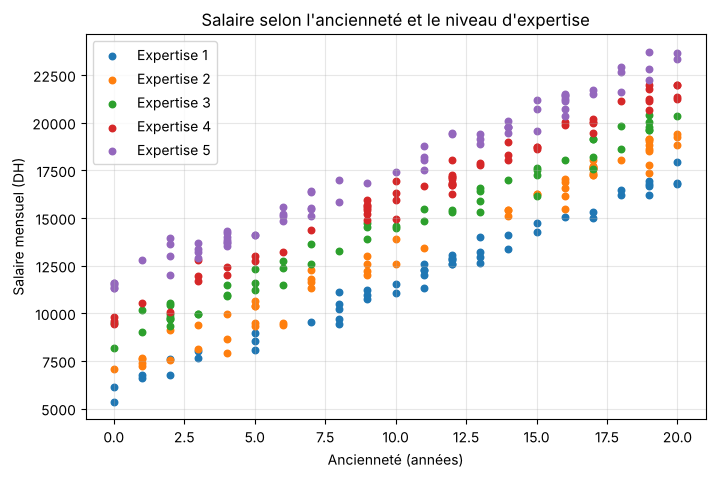

In [2]:
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print(f"Salaire moyen : {y.mean().item():.2f} DH")

plt.figure(figsize=(8, 5))
for niveau in range(1, 6):
    masque = X[:, 1] == niveau
    plt.scatter(
        X[masque, 0].numpy(),
        y[masque, 0].numpy(),
        s=22,
        label=f"Expertise {niveau}"
    )
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("Salaire selon l'ancienneté et le niveau d'expertise")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

2. *Séparer et préparer les données*
Utilisez 80 % des données pour l’entraînement et 20 % pour le test.

Pour faciliter l’apprentissage :

standardisez les entrées à partir des statistiques du jeu d’entraînement ;
exprimez les salaires en milliers de DH.

In [3]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

3. *Construire et entraîner le modèle*

In [4]:
# Deux variables d'entrée et une sortie
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

historique = []

model.train()

for epoch in range(500):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Époque {epoch + 1} | "
            f"Perte : {loss.item():.4f}"
        )

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


Travail demandé :

- Complétez le modèle et la boucle d’entraînement.
- Tracez l’évolution de la perte :


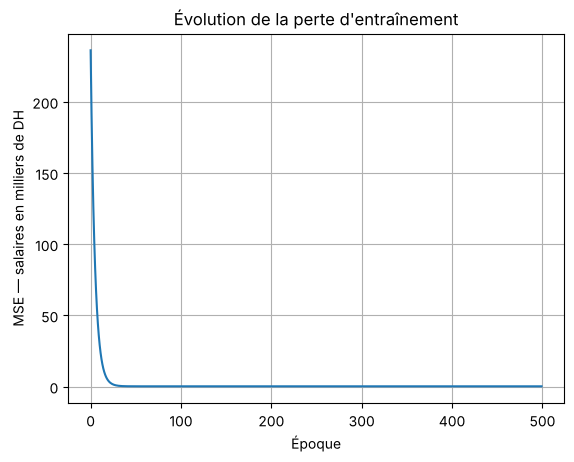

In [5]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

4. Évaluer les prédictions

In [6]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # À compléter
    mae = torch.abs(predictions_dh - salaires_reels_dh).mean()

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.64 DH


Interprétation : une MAE de 400 DH signifie que les prédictions s’écartent, en moyenne, de 400 DH des salaires réels.

5. Prédire le salaire d’un nouveau salarié

Prédisez le salaire d’une personne ayant :

- 7 ans d’ancienneté ;
- un niveau d’expertise de 4/5.

In [7]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")

Salaire estimé : 14201.94 DH


Vérification : d’après la règle de génération, le salaire sans bruit est :

4000 + 600 * 7 + 1500 * 4 = 14200 DH

Votre prédiction devrait être proche de cette valeur.

Questions complémentaires :

- À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?
- Pourquoi la perte ne devient-elle pas exactement nulle ?
- Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?
- Quel effet aurait une augmentation du bruit sur la précision ?
- Retrouvez les coefficients en unités d’origine à partir des paramètres du modèle entraîné. Ils devraient être proches de 600, 1500 et 4000.

Remarque : traiter l’expertise comme une note numérique suppose que chaque passage d’un niveau au suivant a le même effet sur le salaire. Cette hypothèse simplifie l’exercice, mais doit être vérifiée avec des données réelles.

In [8]:
# --- Retrouver les coefficients en unités d'origine -------------------------
# Le modèle a appris : y_k = w1*(anc - mu1)/s1 + w2*(exp - mu2)/s2 + b   (y_k en milliers de DH)
# En développant : coef_i = w_i / s_i  et  intercept = b - sum(w_i * mu_i / s_i)
w = model.weight.detach()[0]
b = model.bias.detach()[0]
mu = moyenne[0]
sigma = ecart_type[0]

coef_anciennete, coef_expertise = (w / sigma * 1000).tolist()
intercept = ((b - (w * mu / sigma).sum()) * 1000).item()

print(f"Effet d'1 année d'ancienneté : {coef_anciennete:.1f} DH  (valeur théorique : 600)")
print(f"Effet d'1 point d'expertise  : {coef_expertise:.1f} DH  (valeur théorique : 1500)")
print(f"Salaire de base (ordonnée)   : {intercept:.1f} DH  (valeur théorique : 4000)")

# --- Extrapolation : 40 ans d'ancienneté (données d'entraînement : 0 à 20 ans) ---
inconnu = torch.tensor([[40.0, 4.0]])
with torch.no_grad():
    pred_40 = model((inconnu - moyenne) / ecart_type) * 1000
print(f"\nPrédiction pour 40 ans / expertise 4 : {pred_40.item():.0f} DH")

# --- Effet du bruit sur la précision ----------------------------------------
def entrainer_et_evaluer(ecart_bruit, graine=0):
    torch.manual_seed(graine)
    anc = torch.randint(0, 21, (n, 1)).float()
    exp = torch.randint(1, 6, (n, 1)).float()
    sal = 4000 + 600 * anc + 1500 * exp + torch.randn(n, 1) * ecart_bruit
    Xb, yb = torch.cat([anc, exp], dim=1), sal / 1000

    idx = torch.randperm(n)
    lim = int(0.8 * n)
    Xtr, Xte, ytr, yte = Xb[idx[:lim]], Xb[idx[lim:]], yb[idx[:lim]], yb[idx[lim:]]
    m_, s_ = Xtr.mean(dim=0, keepdim=True), Xtr.std(dim=0, keepdim=True)
    Xtr, Xte = (Xtr - m_) / s_, (Xte - m_) / s_

    mod = nn.Linear(2, 1)
    crit = nn.MSELoss()
    opt = torch.optim.SGD(mod.parameters(), lr=0.05)
    for _ in range(500):
        opt.zero_grad()
        crit(mod(Xtr), ytr).backward()
        opt.step()
    with torch.no_grad():
        return (torch.abs(mod(Xte) - yte).mean() * 1000).item()

print()
for ecart in (500, 1500, 3000):
    print(f"Bruit (écart-type) = {ecart:4d} DH  ->  MAE test = {entrainer_et_evaluer(ecart):7.1f} DH")

Effet d'1 année d'ancienneté : 592.7 DH  (valeur théorique : 600)
Effet d'1 point d'expertise  : 1490.7 DH  (valeur théorique : 1500)
Salaire de base (ordonnée)   : 4090.3 DH  (valeur théorique : 4000)

Prédiction pour 40 ans / expertise 4 : 33760 DH

Bruit (écart-type) =  500 DH  ->  MAE test =   405.8 DH


Bruit (écart-type) = 1500 DH  ->  MAE test =  1217.3 DH
Bruit (écart-type) = 3000 DH  ->  MAE test =  2434.5 DH


### Réponses — Exercice 1

**1. Effet d'une année d'ancienneté supplémentaire (à expertise constante).**
C'est le coefficient associé à l'ancienneté, une fois ramené en DH : environ **+590 à +600 DH par mois** (la valeur théorique est 600). Les coefficients appris sur les variables *normalisées* ne sont pas directement interprétables ; il faut les diviser par l'écart-type de la variable (et multiplier par 1000 pour repasser en DH).

**2. Pourquoi la perte ne devient-elle pas exactement nulle ?**
Parce que les données contiennent un **bruit aléatoire** (écart-type 500 DH = 0,5 k DH) que les deux variables ne peuvent pas expliquer. Même avec les paramètres parfaits, la MSE ne peut pas descendre sous la variance du bruit : 0,5² = **0,25** (en milliers de DH au carré). On observe bien une perte qui se stabilise autour de 0,24 : le modèle a convergé, il ne peut pas faire mieux. Une perte proche de 0 serait même suspecte (sur-apprentissage).

**3. Le modèle est-il fiable pour 40 ans d'ancienneté ?**
**Non, pas de garantie.** Les données d'entraînement vont de 0 à 20 ans : 40 ans est une **extrapolation**. Un modèle linéaire prolonge mécaniquement la droite (on obtient ≈ 33 800 DH), mais rien ne prouve que la relation reste linéaire hors de la plage observée (plafonds de grille salariale, départ à la retraite, etc.). Un modèle n'est fiable que dans le domaine couvert par ses données d'entraînement.

**4. Effet d'une augmentation du bruit.**
Les coefficients appris restent proches des vrais, mais **les prédictions deviennent moins précises** : l'erreur absolue moyenne augmente à peu près proportionnellement à l'écart-type du bruit (pour un bruit gaussien, MAE ≈ 0,8 × σ, soit ≈ 400 DH pour σ = 500 DH). Le bruit fixe une limite à la précision atteignable, quel que soit l'entraînement.

**5. Coefficients en unités d'origine.**
Voir la cellule de code ci-dessus : on retrouve ≈ 593 (ancienneté), ≈ 1491 (expertise) et ≈ 4090 (base), proches de 600, 1500 et 4000. L'écart vient du bruit et de la taille limitée de l'échantillon (240 points d'entraînement).

###  Exercice 3  — Classification des fleurs Iris 🌸

Objectif : entraîner un réseau de neurones pour prédire l’espèce d’une fleur à partir de quatre mesures :

- longueur et largeur des sépales ;
- longueur et largeur des pétales.

Le jeu de données Iris contient 150 fleurs réparties en trois classes : setosa, versicolor et virginica.


Bibliothèques : torch, scikit-learn.

**1. Préparation des données**

In [6]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


**Questions :**

- Que représentent les quatre colonnes de X_train ?
- Pourquoi utilise-t-on torch.long pour les étiquettes ?
- Pourquoi ne faut-il pas ajuster le StandardScaler sur les données de test ?

**Réponses :**

- **Les quatre colonnes de `X_train`** sont les quatre mesures de chaque fleur (en cm) : longueur du sépale, largeur du sépale, longueur du pétale, largeur du pétale (`iris.feature_names`). Elles ont été standardisées (moyenne 0, écart-type 1). Dimensions : `(120, 4)` pour 120 fleurs d'entraînement.
- **`torch.long` pour les étiquettes** : `CrossEntropyLoss` attend, pour chaque exemple, l'**indice de la classe** (0, 1 ou 2) sous forme d'entiers 64 bits, et non des flottants. La fonction compare cet indice à la ligne de logits correspondante.
- **Ne pas ajuster le `StandardScaler` sur le test** : on utiliserait alors des informations du jeu de test (sa moyenne et son écart-type) pendant la préparation, ce qui est une **fuite de données** (*data leakage*). L'évaluation serait trop optimiste. On calcule les statistiques sur l'entraînement (`fit_transform`) puis on les applique telles quelles au test (`transform`), exactement comme on le fera pour de nouvelles données en production.

**2. Construire le réseau**

In [ ]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

Attention : n’ajoutez pas de Softmax à la sortie. CrossEntropyLoss attend directement les scores bruts, appelés logits.

**3. Entraîner le modèle**

Complétez la boucle d’entraînement. Pour cet exercice, chaque itération utilise toutes les données d’entraînement.

In [11]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    # TODO : remettre les gradients à zéro
    optimizer.zero_grad()

    # TODO : calculer les scores prédits
    logits = model(X_train)

    # TODO : calculer la perte
    loss = criterion(logits, y_train)

    # TODO : calculer les gradients
    loss.backward()

    # TODO : mettre à jour les paramètres
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


**4. Évaluer le classifieur**

Complétez le calcul des prédictions et de l’accuracy, c’est-à-dire la proportion de fleurs correctement classées.

In [12]:
model.eval()

with torch.no_grad():
    logits = model(X_test)

    # TODO : sélectionner la classe au score maximal pour chaque fleur
    predictions = logits.argmax(dim=1)

    # TODO : calculer la proportion de prédictions correctes
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


**5- Autres question :**

- Tracez la courbe de perte.
- Affichez une matrice de confusion.
- Comparez ce réseau à un modèle sans couche cachée : nn.Linear(4, 3).
- Prédisez l’espèce d’une nouvelle fleur de mesures [5.1, 3.5, 1.4, 0.2], après l’avoir normalisée avec le même scaler.

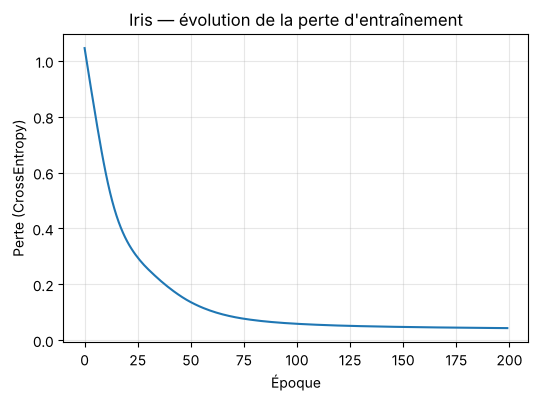

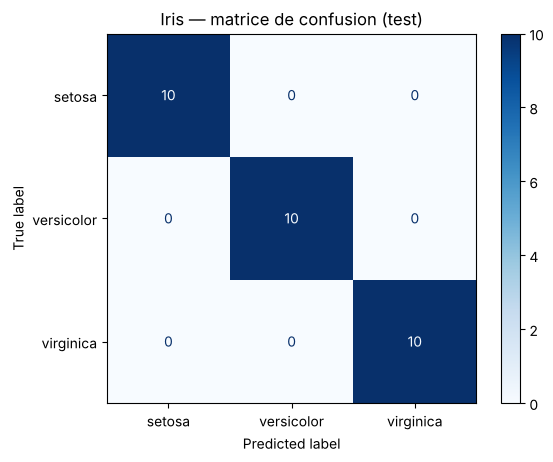

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1) Courbe de perte
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("Perte (CrossEntropy)")
plt.title("Iris — évolution de la perte d'entraînement")
plt.grid(alpha=0.3)
plt.show()

# 2) Matrice de confusion sur le jeu de test
ConfusionMatrixDisplay.from_predictions(
    y_test.numpy(),
    predictions.numpy(),
    display_labels=iris.target_names,
    cmap="Blues"
)
plt.title("Iris — matrice de confusion (test)")
plt.show()

Réseau avec couche cachée : perte finale = 0.0432 | accuracy test = 100.0%
Modèle linéaire Linear(4,3): perte finale = 0.2416 | accuracy test = 90.0%


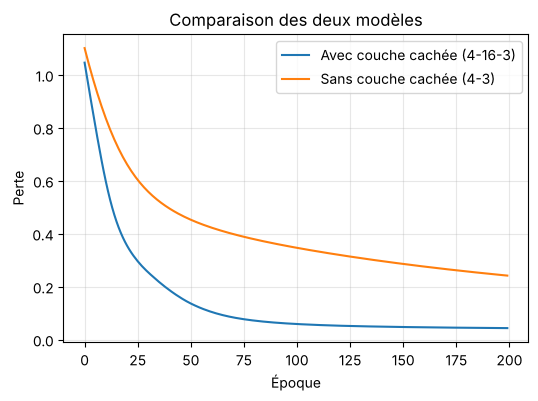

In [14]:
# 3) Comparaison avec un modèle sans couche cachée : nn.Linear(4, 3)
def entrainer(modele, epochs=200, lr=0.01):
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    historique = []

    modele.train()
    for _ in range(epochs):
        opt.zero_grad()
        l = crit(modele(X_train), y_train)
        l.backward()
        opt.step()
        historique.append(l.item())

    modele.eval()
    with torch.no_grad():
        acc = (modele(X_test).argmax(dim=1) == y_test).float().mean().item()
    return historique, acc


torch.manual_seed(42)
model_lineaire = nn.Linear(4, 3)
losses_lin, acc_lin = entrainer(model_lineaire)

print(f"Réseau avec couche cachée : perte finale = {losses[-1]:.4f} | accuracy test = {accuracy.item():.1%}")
print(f"Modèle linéaire Linear(4,3): perte finale = {losses_lin[-1]:.4f} | accuracy test = {acc_lin:.1%}")

plt.figure(figsize=(6, 4))
plt.plot(losses, label="Avec couche cachée (4-16-3)")
plt.plot(losses_lin, label="Sans couche cachée (4-3)")
plt.xlabel("Époque")
plt.ylabel("Perte")
plt.legend()
plt.grid(alpha=0.3)
plt.title("Comparaison des deux modèles")
plt.show()

In [15]:
# 4) Prédire l'espèce d'une nouvelle fleur (après normalisation avec le MÊME scaler)
nouvelle_fleur = torch.tensor(
    scaler.transform([[5.1, 3.5, 1.4, 0.2]]),
    dtype=torch.float32
)

model.eval()
with torch.no_grad():
    probabilites = torch.softmax(model(nouvelle_fleur), dim=1)
    classe = probabilites.argmax(dim=1).item()

print("Espèce prédite :", iris.target_names[classe])
print("Probabilités   :", {str(nom): round(p, 4) for nom, p in zip(iris.target_names, probabilites[0].tolist())})

Espèce prédite : setosa
Probabilités   : {'setosa': 0.9999, 'versicolor': 0.0001, 'virginica': 0.0}


**Commentaires :**

- **Courbe de perte** : elle décroît rapidement puis se stabilise vers 0,04 : le réseau a convergé.
- **Matrice de confusion** : la diagonale concentre (presque) tous les exemples. Sur Iris, *setosa* est toujours parfaitement séparée ; les rares erreurs éventuelles concernent *versicolor* / *virginica*, dont les mesures se chevauchent.
- **Comparaison** : le modèle linéaire `nn.Linear(4, 3)` apprend aussi (les classes sont presque linéairement séparables), mais sa perte reste plus élevée (≈ 0,24 contre ≈ 0,04) et son accuracy plus faible (≈ 90 % contre ≈ 100 % ici). La couche cachée + ReLU apporte de la non-linéarité. Attention : le test ne contient que 30 fleurs, donc un écart de quelques points correspond à 1 ou 2 exemples et reste à nuancer.
- **Nouvelle fleur `[5.1, 3.5, 1.4, 0.2]`** : prédite **setosa** avec une probabilité très proche de 1 (pétales très petits, caractéristique de cette espèce).

### Exercice 2 : Classifier les chiffres MNIST
Objectif : utiliser des mini-lots et évaluer un modèle sur des données de test.

Chargement des données

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

#### Travail demandé : 
- Entraînez le modèle pendant 5 époques.
- Utilisez model.train() pendant l’entraînement.
- Évaluez-le avec model.eval() et torch.no_grad().
- Obtenez les classes prédites avec :
   - predicted_classes = outputs.argmax(dim=1)
   - Calculez mes métriques Accuracy, Recall, Precision et f1-Score sur le jeu de test.
   - Afficher la matrice de confusion
   - Affichez quelques images mal classées.
- Sauvegarder et recharger un modèle : réutiliser un réseau entraîné sans recommencer l’apprentissage.

Attention : CrossEntropyLoss attend les sorties brutes du réseau, sans Softmax, et des étiquettes entières.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# On place le modèle sur le bon appareil puis on (re)crée l'optimiseur
model = model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 5
historique_perte = []

for epoch in range(epochs):
    model.train()
    perte_totale = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()              # 1. remettre les gradients à zéro
        outputs = model(images)            # 2. scores bruts (logits)
        loss = criterion(outputs, labels)  # 3. perte
        loss.backward()                    # 4. gradients
        optimizer.step()                   # 5. mise à jour

        perte_totale += loss.item() * images.size(0)

    perte_moyenne = perte_totale / len(train_dataset)
    historique_perte.append(perte_moyenne)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {perte_moyenne:.4f}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)


def predire(modele, loader):
    """Retourne (classes prédites, vraies classes) sur tout un DataLoader."""
    modele.eval()
    toutes_predictions, tous_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = modele(images.to(device))
            predicted_classes = outputs.argmax(dim=1)
            toutes_predictions.append(predicted_classes.cpu())
            tous_labels.append(labels)
    return torch.cat(toutes_predictions).numpy(), torch.cat(tous_labels).numpy()


y_pred, y_true = predire(model, test_loader)

# Multi-classe (10 classes) : on moyenne les métriques par classe (macro)
print(f"Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision : {precision_score(y_true, y_pred, average='macro'):.4f}  (macro)")
print(f"Recall    : {recall_score(y_true, y_pred, average='macro'):.4f}  (macro)")
print(f"F1-score  : {f1_score(y_true, y_pred, average='macro'):.4f}  (macro)")
print()
print(classification_report(y_true, y_pred, digits=4))

In [ ]:
# Matrice de confusion
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, cmap="Blues", ax=ax)
ax.set_title("MNIST (MLP) — matrice de confusion sur le test")
plt.show()

In [ ]:
# Quelques images mal classées
indices_erreurs = np.where(y_pred != y_true)[0][:10]

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, i in zip(axes.ravel(), indices_erreurs):
    image, _ = test_dataset[i]          # test_loader n'est pas mélangé : mêmes indices
    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(f"Vrai : {y_true[i]} | Prédit : {y_pred[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Sauvegarder les paramètres (state_dict) puis les recharger dans un nouveau modèle
chemin = "mnist_mlp.pth"
torch.save(model.state_dict(), chemin)
print("Modèle sauvegardé dans", chemin)

# Même architecture, poids initialisés au hasard...
modele_recharge = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

# ...puis remplacés par les poids sauvegardés, sans réentraîner
modele_recharge.load_state_dict(torch.load(chemin, map_location=device, weights_only=True))

y_pred_rec, _ = predire(modele_recharge, test_loader)
print("Prédictions identiques au modèle entraîné :", np.array_equal(y_pred, y_pred_rec))
print(f"Accuracy du modèle rechargé : {accuracy_score(y_true, y_pred_rec):.4f}")

### Exercice 4 — Classification MNIST avec un CNN

Objectif : construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

MNIST contient 60 000 images d’entraînement et 10 000 images de test, en niveaux de gris, de taille 28 × 28 pixels.

**1. Chargement des données**

In [8]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Questions :**

- Que représentent les quatre dimensions du tenseur images ?
- Pourquoi mélanger les données d’entraînement avec shuffle=True ?

**Réponses :**

- **Les 4 dimensions de `images`** : `[64, 1, 28, 28]` = **(taille du lot, canaux, hauteur, largeur)**. Ici 64 images par mini-lot, 1 canal (niveaux de gris, contre 3 pour une image RVB), 28 × 28 pixels.
- **Pourquoi `shuffle=True` ?** Pour que les mini-lots soient différents à chaque époque et ne dépendent pas de l'ordre du jeu de données. Sans mélange, le modèle verrait toujours les mêmes lots dans le même ordre (parfois regroupés par classe), ce qui rend les gradients corrélés d'un lot à l'autre, ralentit ou déstabilise l'apprentissage et peut le faire « suivre » l'ordre des données. On ne mélange pas le jeu de test : l'ordre n'a pas d'influence sur l'évaluation.

**2. Visualiser quelques images**

Complétez l’affichage des étiquettes :

In [ ]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : { labels[i].item() }")
    ax.axis("off")

plt.tight_layout()
plt.show()

**3. Construire le CNN**

Implémentez cette architecture :

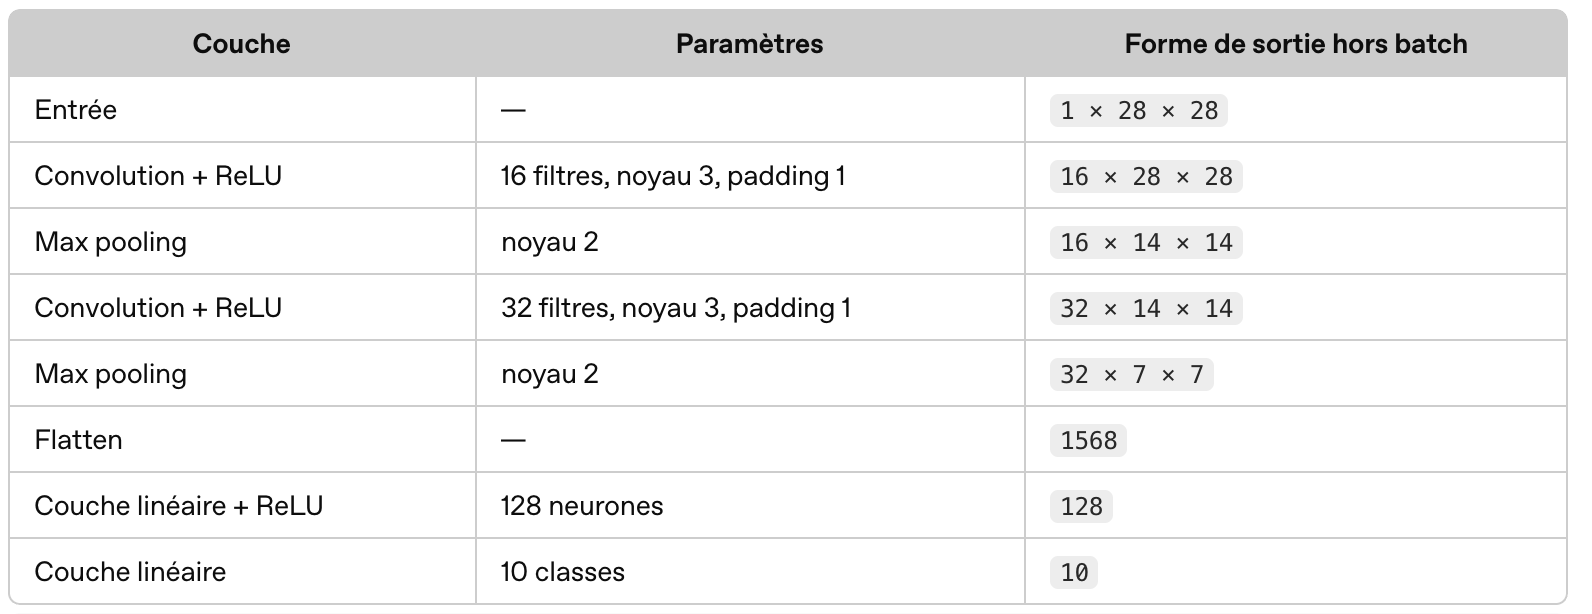

In [ ]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)

# Vérifier la forme de sortie
with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)

**Question :** pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?

Attention : n’ajoutez pas de Softmax au modèle. CrossEntropyLoss attend les scores bruts, appelés logits.

**Réponse :** les convolutions utilisent `kernel_size=3` avec `padding=1`, donc elles **conservent** la taille spatiale ; seuls les `MaxPool2d(2)` la réduisent (division par 2 à chaque fois) :

`28 × 28` → pool → `14 × 14` → pool → `7 × 7`.

La seconde convolution produit **32 cartes de caractéristiques** (canaux) de taille 7 × 7. Après `Flatten`, on obtient donc 32 × 7 × 7 = **1568 valeurs par image**, ce qui fixe `in_features` de la première couche linéaire.

**4. Entraîner le réseau**

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Réinitialiser les gradients
        optimizer.zero_grad()

        # 2. Calculer les scores
        logits = model(images)

        # 3. Calculer la perte
        loss = criterion(logits, labels)

        # 4. Calculer les gradients
        loss.backward()

        # 5. Mettre à jour les paramètres
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)

    print(
        f"Époque {epoch + 1}/{epochs} "
        f"| Perte : {average_loss:.4f}"
    )

**5. Évaluer sur le jeu de test**

In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        # Classe ayant le score le plus élevé
        predictions = logits.argmax(dim=1)

        # Compter les bonnes prédictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = correct / total
print(f"Accuracy sur le test : {accuracy:.2%}")

**Indices :**

- argmax(dim=1) sélectionne une classe pour chaque image ;
(predictions == labels).sum().item() compte les prédictions correctes.

- Résultat attendu : une accuracy généralement supérieure à 97 % après quelques époques, sans garantie exacte.

**Autres questions :**

- Affichez 10 images mal classées, avec leur vraie classe et la prédiction.
- Ajoutez une couche Dropout avant la dernière couche linéaire.
- Sauvegardez les paramètres avec torch.save(model.state_dict(), "mnist_cnn.pth").

In [ ]:
import numpy as np


def predire(modele, loader):
    """Retourne (classes prédites, vraies classes) sur tout un DataLoader."""
    modele.eval()
    preds, labs = [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            preds.append(modele(imgs.to(device)).argmax(dim=1).cpu())
            labs.append(lbls)
    return torch.cat(preds).numpy(), torch.cat(labs).numpy()


# 1) 10 images mal classées, avec vraie classe et prédiction
y_pred, y_true = predire(model, test_loader)
indices_erreurs = np.where(y_pred != y_true)[0][:10]
print(f"Nombre d'erreurs sur le test : {(y_pred != y_true).sum()} / {len(y_true)}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, i in zip(axes.ravel(), indices_erreurs):
    image = test_dataset[i][0][0] * 0.3081 + 0.1307   # annuler la normalisation
    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Vrai : {y_true[i]} | Prédit : {y_pred[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# 3) Sauvegarder les paramètres, puis les recharger sans réentraîner
torch.save(model.state_dict(), "mnist_cnn.pth")
print("Paramètres sauvegardés dans mnist_cnn.pth")

modele_recharge = MNISTClassifier().to(device)
modele_recharge.load_state_dict(torch.load("mnist_cnn.pth", map_location=device, weights_only=True))

y_pred_rec, _ = predire(modele_recharge, test_loader)
print("Prédictions identiques :", np.array_equal(y_pred, y_pred_rec))
print(f"Accuracy du modèle rechargé : {(y_pred_rec == y_true).mean():.2%}")

In [ ]:
# 2) Ajouter une couche Dropout avant la dernière couche linéaire
class MNISTClassifierDropout(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p),          # <- Dropout juste avant la dernière couche linéaire
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


torch.manual_seed(42)
model_dropout = MNISTClassifierDropout(p=0.3).to(device)
optimizer_d = torch.optim.Adam(model_dropout.parameters(), lr=0.001)

for epoch in range(3):
    model_dropout.train()          # Dropout ACTIF pendant l'entraînement
    total_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_d.zero_grad()
        loss = criterion(model_dropout(images), labels)
        loss.backward()
        optimizer_d.step()
        total_loss += loss.item() * images.size(0)
    print(f"Époque {epoch + 1}/3 | Perte : {total_loss / len(train_dataset):.4f}")

# predire() appelle model.eval() : Dropout INACTIF pendant l'évaluation
y_pred_d, _ = predire(model_dropout, test_loader)
print(f"\nAccuracy sans Dropout : {(y_pred == y_true).mean():.2%}")
print(f"Accuracy avec Dropout : {(y_pred_d == y_true).mean():.2%}")

**Commentaires :**

- **Images mal classées** : ce sont en général des chiffres ambigus ou mal écrits (un 4 « ouvert » proche d'un 9, un 7 avec barre proche d'un 1, etc.) que même un humain hésiterait à lire.
- **Dropout** : pendant `model.train()`, il met aléatoirement à zéro une fraction `p` des neurones, ce qui limite la co-adaptation des neurones et réduit le sur-apprentissage ; pendant `model.eval()` il est désactivé. Sur MNIST avec seulement 3 époques, le gain en accuracy est faible (voire nul), car le modèle n'a pas encore sur-appris : l'effet du Dropout se voit surtout sur des entraînements plus longs ou des réseaux plus gros.
- **Sauvegarde** : `state_dict()` ne contient que les poids. Pour recharger, on recrée d'abord l'architecture identique, puis on appelle `load_state_dict(...)` ; les prédictions sont alors exactement les mêmes que celles du modèle entraîné.